# Reinforcement Learning: Deep RL on a CPU (DQN, REINFORCE, A2C, PPO from scratch)

> **Who is this for:** you have done the tabular algorithms in [`09_tabular_rl_from_scratch`](09_tabular_rl_from_scratch.ipynb) and read the theory in [`04_deep_q_networks`](04_deep_q_networks.ipynb) and [`05_policy_gradient`](05_policy_gradient.ipynb). Now you want to **write the deep-RL algorithms yourself**, train them on a laptop CPU, and learn to evaluate and debug them like a researcher. It also suits MS students and interview preparation for RL or RLHF roles.
>
> **What you will learn:**
> - The `CartPole-v1` task, with random and hand-written heuristic baselines, and a tiny **vectorised environment** that handles `terminated` vs `truncated` correctly
> - **DQN from scratch:** replay buffer, target network, Huber loss, ε schedule; then **Double DQN**, with a direct measurement of Q-value **overestimation**
> - **REINFORCE**, with and without a learned **baseline**, including a measurement of how much the baseline reduces gradient variance
> - **A2C** (advantage actor-critic with an entropy bonus) and a compact **PPO** (clipped objective, **GAE**), with the diagnostics practitioners watch (clip fraction, approximate KL)
> - **Evaluating RL properly:** several seeds, **interquartile mean (IQM)**, bootstrap confidence intervals, learning curves with bands
> - **Hyperparameter sensitivity:** a small learning-rate × rollout-size grid and a γ sweep
> - **Debugging RL:** reward scale and value-loss explosions, observation normalisation, a checklist
> - **[optional]** the same task with **Stable-Baselines3**: train, save, load, roll out
>
> **Prerequisites:** [PyTorch from zero](../05_Deep_Learning/00_start_here_pytorch_from_zero.ipynb), [tabular RL](09_tabular_rl_from_scratch.ipynb) (Q-learning, TD(λ)), [policy-gradient theory](05_policy_gradient.ipynb). Basic statistics (mean, standard error, bootstrap) from [`24_Research_Methods/03`](../24_Research_Methods/03_statistical_significance_and_reporting.ipynb) helps in section 6.
>
> **Time needed:** about 3–4 hours.
>
> **Runs on:** CPU only, no API key, no internet. PyTorch, `gymnasium`, NumPy, pandas, matplotlib; Stable-Baselines3 is optional. Every training run is small (at most a few tens of thousands of environment steps). Expect about 5–10 minutes for the whole notebook on a laptop.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

In the previous notebook the agent kept a **table** with one row for every situation. That works for a 4×12 grid, but not for a robot arm or a video game, where situations are described by real numbers and almost never repeat exactly. **Deep RL** replaces the table with a small **neural network** that looks at the situation and *guesses* the score of each action (DQN) or directly outputs which action to take (policy-gradient methods such as PPO).

Two everyday examples. A cyclist does not memorise every possible combination of speed and lean angle; they get a *feel* that generalises to new situations, which is what the network gives the agent. A basketball coach watching game videos does not just say "you won" or "you lost", but "that pass was better than average"; that "better than average" signal is the **advantage** used by A2C and PPO.

**Tiny example.** In CartPole the agent sees 4 numbers, e.g. `[cart position 0.02, cart speed −0.15, pole angle 0.03, pole spin 0.21]`, and chooses "push left" or "push right". It earns +1 for every step the pole stays up, up to 500. A random agent scores about 20; the PPO agent you will train typically scores 400–500.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| DQN | a neural network that guesses "how many points will I get if I press this button?" | Atari game agents, recommendation and bidding systems |
| Policy gradient (REINFORCE, PPO) | make actions that turned out better than expected more likely | robot control, **RLHF for ChatGPT-style models** |
| Seeds and confidence intervals | run the experiment several times, because RL results are very noisy | every credible RL paper and product A/B test |

### How this notebook is different from `04` and `05`
[`04_deep_q_networks`](04_deep_q_networks.ipynb) and [`05_policy_gradient`](05_policy_gradient.ipynb) explain the theory and the zoo of variants (Rainbow, TRPO, SAC, TD3). Here we implement the four workhorses **from scratch**, keep them small enough for a CPU, and spend real time on the part papers often skip: **evaluation, sensitivity and debugging**. [`08_industry_inventory_control_with_rl`](08_industry_inventory_control_with_rl.ipynb) then shows a production-style project with Stable-Baselines3.

## Table of contents
1. CartPole, baselines and a tiny vectorised environment
2. DQN and Double DQN
3. REINFORCE and the baseline trick
4. A2C: advantage actor-critic
5. PPO with GAE
6. Evaluating RL properly: seeds, IQM, confidence intervals
7. Hyperparameter sensitivity
8. Debugging RL
9. [optional] Stable-Baselines3 comparison, save and load
10. Summary table
11. How this connects to modern AI
12. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import math, time, random, copy, sys, os, tempfile, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import gymnasium as gym

torch.set_num_threads(1)        # tiny networks run FASTEST on one thread (less overhead); never use more than 2 on a shared machine
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "figure.dpi": 100})
pd.set_option("display.width", 140)
NOTEBOOK_START = time.time()
print("torch", torch.__version__, "| gymnasium", gym.__version__, "| threads", torch.get_num_threads())

torch 2.12.1+cpu | gymnasium 1.4.0 | threads 1


## 1. CartPole, baselines and a tiny vectorised environment

> 💬 **In plain English:** meet the balancing-pole game, measure how well a random player and a simple rule do, and build a helper that runs several games at once.

**CartPole-v1** (Barto, Sutton & Anderson, 1983) is the "hello world" of deep RL:

| | |
|---|---|
| Observation (4 real numbers) | cart position $x$, cart velocity $\dot x$, pole angle $\theta$, pole angular velocity $\dot\theta$ |
| Actions (2) | 0 = push cart left, 1 = push cart right |
| Reward | +1 for every step the pole is still up |
| `terminated` | pole angle beyond ±12° or cart beyond ±2.4 (a real failure) |
| `truncated` | the 500-step time limit (not a failure, just the end of the clock) |
| "Solved" | average return ≥ 475 over 100 episodes (the v1 threshold) |

Before any learning, always measure **baselines**: a random policy, and a simple hand-written rule. If your fancy agent cannot beat a two-line heuristic, something is wrong.

In [2]:
def run_episode(env, policy, seed=None):
    """Play one episode with policy(obs) -> action; return the total reward."""
    obs, _ = env.reset(seed=seed); total, done = 0.0, False
    while not done:
        obs, r, terminated, truncated, _ = env.step(policy(obs))
        total += r; done = terminated or truncated
    return total

def evaluate(policy, n_episodes=10, seed=10_000):
    """Average return over n evaluation episodes with FIXED seeds (so every agent faces the same starts)."""
    env = gym.make("CartPole-v1")
    return float(np.mean([run_episode(env, policy, seed=seed + i) for i in range(n_episodes)]))

rng = np.random.default_rng(0)
random_policy = lambda obs: int(rng.integers(2))
heuristic_policy = lambda obs: int(obs[2] + 0.5 * obs[3] > 0)     # push towards the side the pole is falling to

baselines = {"random": evaluate(random_policy, 20), "heuristic (θ + 0.5·θ̇ > 0)": evaluate(heuristic_policy, 20)}
print(pd.Series(baselines, name="mean return over 20 episodes").round(1).to_string())
env = gym.make("CartPole-v1"); obs, _ = env.reset(seed=0)
print("\nobservation space:", env.observation_space, "\nexample observation:", obs.round(3))

random                         18.2
heuristic (θ + 0.5·θ̇ > 0)    500.0

observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32) 
example observation: [ 0.014 -0.023 -0.046 -0.048]


**What just happened?** A random agent keeps the pole up for about 20 steps. A one-line physics-inspired rule ("push towards the side the pole is falling to, looking a little ahead using the angular velocity") keeps it up for the full 500 steps on every evaluation episode. CartPole is close to a linear control problem, so a hand-written controller can solve it. The point of RL is to learn such a controller **from reward alone**, with no physics knowledge, and the same algorithms then work where nobody can write the rule by hand. Always know your heuristic baseline: an RL agent that cannot match it is not ready for production.

### A minimal vectorised environment
Running several copies of the environment in lock-step (a **vectorised environment**) lets one forward pass of the network choose actions for all copies at once, which is much faster on a CPU and gives more diverse data per update. Two details matter:

1. **Auto-reset:** when one copy finishes, it restarts immediately so the batch never has holes.
2. **`terminated` vs `truncated`:** when the time limit ends an episode, the state was *not* bad. The value target should still **bootstrap** from the final observation: $r + \gamma V(s_{\text{final}})$, not just $r$. Treating truncation as failure teaches the agent that step 500 is a cliff, a classic silent bug.

In [3]:
class SimpleVecEnv:
    """N CartPole copies stepped together. step() returns the next observations (already reset where an episode ended),
    rewards, terminated, truncated, and the TRUE final observations (needed for bootstrapping at truncation)."""
    def __init__(self, n_envs, seed, env_id="CartPole-v1", wrapper=None):
        self.envs = [gym.make(env_id) for _ in range(n_envs)]
        if wrapper is not None:
            self.envs = [wrapper(e) for e in self.envs]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)]).astype(np.float32)
        self.running_return = np.zeros(n_envs)
        self.episode_returns, self.episode_end_steps = [], []    # finished episodes, for learning curves
        self.total_steps = 0

    def step(self, actions):
        n = len(self.envs)
        rewards, term, trunc = np.zeros(n, np.float32), np.zeros(n, bool), np.zeros(n, bool)
        final_obs = np.zeros_like(self.obs)
        for i, (env, a) in enumerate(zip(self.envs, actions)):
            obs, r, terminated, truncated, info = env.step(int(a))
            rewards[i], term[i], trunc[i], final_obs[i] = r, terminated, truncated, obs
            self.running_return[i] += info.get("raw_reward", r)    # wrappers may rescale r; log the real score
            if terminated or truncated:
                self.episode_returns.append(self.running_return[i]); self.running_return[i] = 0.0
                self.episode_end_steps.append(self.total_steps + i + 1)
                obs, _ = env.reset()                                 # auto-reset
            self.obs[i] = obs
        self.total_steps += n
        return self.obs.copy(), rewards, term, trunc, final_obs

venv = SimpleVecEnv(4, seed=0)
for _ in range(60):
    venv.step(np.random.randint(0, 2, 4))
print(f"After 60 vector steps (240 env steps): {len(venv.episode_returns)} episodes finished, returns {np.round(venv.episode_returns, 0)}")

def learning_curve(venv, window=20):
    """Moving average of finished-episode returns, indexed by environment steps."""
    r = np.array(venv.episode_returns); s = np.array(venv.episode_end_steps)
    if len(r) < window:
        return s, r
    return s[window - 1:], np.convolve(r, np.ones(window) / window, mode="valid")

After 60 vector steps (240 env steps): 10 episodes finished, returns [10. 13. 23. 16. 26. 41. 24. 12. 21. 12.]


## 2. DQN and Double DQN

> 💬 **In plain English:** teach a neural network to guess the future score of each button, learning from a memory of past moves.

**Deep Q-Network (DQN)** (Mnih et al., *Nature* 2015) is Q-learning with a neural network $Q_\theta(s, a)$. Plain "neural Q-learning" is unstable for two reasons, and DQN adds one fix for each:

| Problem | DQN's fix |
|---|---|
| Consecutive samples are strongly correlated, and old experience is thrown away | **Experience replay:** store transitions in a buffer and train on random mini-batches |
| The target $r + \gamma \max_{a'} Q_\theta(s', a')$ moves every time θ changes ("chasing your own tail") | **Target network** $Q_{\bar\theta}$: a frozen copy used for targets, refreshed every C steps |

Loss: **Huber loss** (quadratic for small errors, linear for large ones, so a few huge TD errors cannot blow up the gradient) on

$$y = r + \gamma\,(1 - \text{terminated})\,\max_{a'} Q_{\bar\theta}(s', a').$$

**Double DQN** (van Hasselt et al., 2016) fixes **overestimation**: $\max$ over noisy estimates is biased upwards, because whichever action is noisily too high gets picked. Double DQN *selects* the action with the online network and *evaluates* it with the target network:

$$y = r + \gamma\,(1 - \text{terminated})\,Q_{\bar\theta}\big(s', \arg\max_{a'} Q_\theta(s', a')\big).$$

It is the deep version of Double Q-learning (practice problem 5 of the tabular notebook).

In [4]:
class ReplayBuffer:
    """Fixed-size ring buffer of transitions stored in NumPy arrays (fast to sample)."""
    def __init__(self, capacity, obs_dim, seed=0):
        self.s = np.zeros((capacity, obs_dim), np.float32); self.s2 = np.zeros((capacity, obs_dim), np.float32)
        self.a = np.zeros(capacity, np.int64); self.r = np.zeros(capacity, np.float32); self.d = np.zeros(capacity, np.float32)
        self.capacity, self.ptr, self.size = capacity, 0, 0
        self.rng = np.random.default_rng(seed)
    def add(self, s, a, r, s2, done):
        self.s[self.ptr], self.a[self.ptr], self.r[self.ptr], self.s2[self.ptr], self.d[self.ptr] = s, a, r, s2, done
        self.ptr = (self.ptr + 1) % self.capacity          # overwrite the oldest transition when full
        self.size = min(self.size + 1, self.capacity)
    def sample(self, batch_size):
        idx = self.rng.integers(0, self.size, batch_size)
        return (torch.as_tensor(self.s[idx]), torch.as_tensor(self.a[idx]), torch.as_tensor(self.r[idx]),
                torch.as_tensor(self.s2[idx]), torch.as_tensor(self.d[idx]))

def mlp(n_in, n_out, hidden=64, act=nn.Tanh):
    return nn.Sequential(nn.Linear(n_in, hidden), act(), nn.Linear(hidden, hidden), act(), nn.Linear(hidden, n_out))

def train_dqn(total_steps=24_000, double=False, seed=0, n_envs=4, lr=5e-4, gamma=0.99, batch_size=64,
              buffer_size=50_000, learning_starts=1_000, target_every=1_000, eps_end=0.05, eps_fraction=0.3):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    venv = SimpleVecEnv(n_envs, seed=seed * 1000)
    q = mlp(4, 2, 128, nn.ReLU); q_target = copy.deepcopy(q)               # online and target networks
    opt = torch.optim.Adam(q.parameters(), lr=lr)
    buffer = ReplayBuffer(buffer_size, 4, seed)
    obs, losses = venv.obs.copy(), []
    for step in range(0, total_steps, n_envs):
        eps = max(eps_end, 1.0 - step / (eps_fraction * total_steps) * (1.0 - eps_end))   # linear ε schedule
        with torch.no_grad():
            greedy = q(torch.as_tensor(obs)).argmax(1).numpy()
        actions = np.where(rng.random(n_envs) < eps, rng.integers(0, 2, n_envs), greedy)
        next_obs, rewards, term, trunc, final_obs = venv.step(actions)
        for i in range(n_envs):                                              # store the TRUE next state;
            buffer.add(obs[i], actions[i], rewards[i], final_obs[i], float(term[i]))   # done = terminated only
        obs = next_obs
        if step >= learning_starts:
            s, a, r, s2, d = buffer.sample(batch_size)
            with torch.no_grad():
                if double:                                                   # select with online, evaluate with target
                    a2 = q(s2).argmax(1, keepdim=True)
                    next_q = q_target(s2).gather(1, a2).squeeze(1)
                else:                                                        # select AND evaluate with target
                    next_q = q_target(s2).max(1).values
                y = r + gamma * (1.0 - d) * next_q
            pred = q(s).gather(1, a[:, None]).squeeze(1)
            loss = F.smooth_l1_loss(pred, y)                                 # Huber loss
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(q.parameters(), 10.0); opt.step()
            losses.append(loss.item())
        if step % target_every < n_envs:
            q_target.load_state_dict(q.state_dict())                         # hard target update
    return q, venv, losses

t0 = time.time()
dqn_q, dqn_venv, dqn_losses = train_dqn(double=False)
t_dqn = time.time() - t0
ddqn_q, ddqn_venv, ddqn_losses = train_dqn(double=True)
t_ddqn = time.time() - t0 - t_dqn
greedy_of = lambda qnet: (lambda o: int(qnet(torch.as_tensor(o, dtype=torch.float32)).argmax()))
with torch.no_grad():
    dqn_eval, ddqn_eval = evaluate(greedy_of(dqn_q)), evaluate(greedy_of(ddqn_q))
print(f"DQN:        {t_dqn:.0f} s, {len(dqn_venv.episode_returns)} training episodes, greedy evaluation return {dqn_eval:.1f}")
print(f"Double DQN: {t_ddqn:.0f} s, {len(ddqn_venv.episode_returns)} training episodes, greedy evaluation return {ddqn_eval:.1f}")

DQN:        32 s, 249 training episodes, greedy evaluation return 177.6
Double DQN: 30 s, 273 training episodes, greedy evaluation return 224.3


            mean predicted max Q  mean actual discounted return  overestimation
DQN                        21.25                          53.15          -31.90
Double DQN                 21.20                          60.24          -39.04


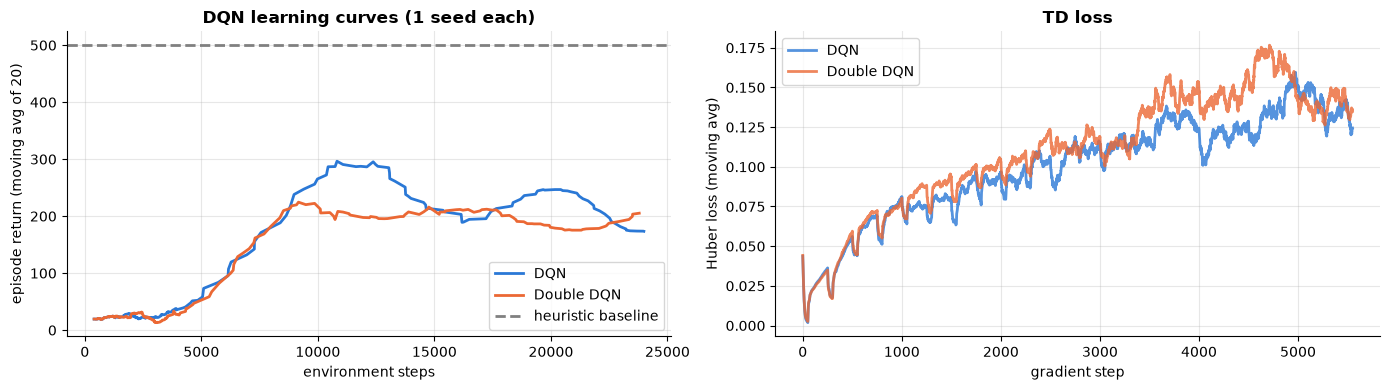

In [5]:
@torch.no_grad()
def overestimation(qnet, n_episodes=5, gamma=0.99, seed=20_000):
    """Compare the network's predicted value max_a Q(s,a) with the discounted return actually obtained from s
    when following the greedy policy. Only states whose remaining episode is long enough (or ends in a real
    failure) are used, so the time limit does not cut the true return short."""
    env, pred, actual = gym.make("CartPole-v1"), [], []
    for i in range(n_episodes):
        obs, _ = env.reset(seed=seed + i); states, rewards, done = [], [], False
        while not done:
            states.append(obs)
            obs, r, term, trunc, _ = env.step(int(qnet(torch.as_tensor(obs)).argmax())); rewards.append(r); done = term or trunc
        G, rtg = 0.0, []
        for r in reversed(rewards):
            G = r + gamma * G; rtg.append(G)
        rtg = rtg[::-1]
        usable = len(states) if term else max(0, len(states) - 400)      # gamma^400 ≈ 0.018: the cut-off tail is negligible
        pred += qnet(torch.as_tensor(np.array(states[:usable]))).max(1).values.tolist(); actual += rtg[:usable]
    return float(np.mean(pred)), float(np.mean(actual))

over = pd.DataFrame({name: dict(zip(["mean predicted max Q", "mean actual discounted return"], overestimation(net)))
                     for name, net in [("DQN", dqn_q), ("Double DQN", ddqn_q)]}).T
over["overestimation"] = over.iloc[:, 0] - over.iloc[:, 1]
print(over.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, v in [("DQN", dqn_venv), ("Double DQN", ddqn_venv)]:
    axes[0].plot(*learning_curve(v), label=name)
for name, l in [("DQN", dqn_losses), ("Double DQN", ddqn_losses)]:
    axes[1].plot(np.convolve(l, np.ones(200) / 200, mode="valid"), label=name, alpha=0.8)
axes[0].axhline(baselines["heuristic (θ + 0.5·θ̇ > 0)"], color="grey", ls="--", label="heuristic baseline")
axes[0].set_xlabel("environment steps"); axes[0].set_ylabel("episode return (moving avg of 20)"); axes[0].set_title("DQN learning curves (1 seed each)"); axes[0].legend()
axes[1].set_xlabel("gradient step"); axes[1].set_ylabel("Huber loss (moving avg)"); axes[1].set_title("TD loss"); axes[1].legend()
plt.tight_layout(); plt.show()

**What just happened?** Both agents learn from scratch, but look at the curves honestly. DQN on CartPole typically improves, then **wobbles or even collapses** for a while, and a single seed of either variant can end up better than the other. The **TD loss does not go steadily down** as in supervised learning, because the targets change as the policy improves and the agent visits new states. Never use the loss alone to judge an RL agent.

The table compares the network's own estimate $\max_a Q(s,a)$ with the discounted return the greedy policy actually obtained from the same states. Here **both networks *underestimate***: after only 24k steps the policy has improved faster than the bootstrapped values could catch up (each target only looks one step ahead, so value information propagates slowly). The two networks are close, so this short run cannot show the effect Double DQN targets. Overestimation appears when the estimates are noisy around their true values, and the next cell isolates it in a controlled experiment.

### Maximisation bias in a controlled experiment
Suppose all 10 actions have the same true value 0, and our estimates are the true value plus noise. The single estimator $\max_a \hat Q(a)$ is biased upwards. The **double estimator** uses one noisy copy to *choose* the action and an independent copy to *evaluate* it (exactly Double DQN's online/target split), and is unbiased here.

In [6]:
rng_b = np.random.default_rng(0)
rows = []
for noise in [0.5, 1.0, 2.0]:
    Q1 = rng_b.normal(0, noise, (100_000, 10))                   # estimates of 10 actions whose TRUE value is 0
    Q2 = rng_b.normal(0, noise, (100_000, 10))                   # an independent second estimate (e.g. the target net)
    single = Q1.max(1).mean()                                    # DQN-style: choose and evaluate with the same estimate
    double = Q2[np.arange(len(Q1)), Q1.argmax(1)].mean()         # Double-DQN-style: choose with Q1, evaluate with Q2
    rows.append({"noise std": noise, "true max value": 0.0, "single estimator E[max]": single, "double estimator": double})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 noise std  true max value  single estimator E[max]  double estimator
       0.5             0.0                    0.770            -0.001
       1.0             0.0                    1.536            -0.002
       2.0             0.0                    3.082             0.000


**What just happened?** With 10 equally good actions, the max of noisy estimates is about 1.54 noise standard deviations above the truth (the expected maximum of 10 standard normals), and the bias grows with the noise. Selecting with one estimate and evaluating with an independent one removes it. In DQN the bias compounds through bootstrapping (each target takes a max over already-biased values), which is why Double DQN helps most on tasks with many actions and noisy rewards, such as Atari.

**Complexity.** Each gradient step costs $O(B \cdot |\theta|)$ for batch size $B$; memory is $O(\text{buffer size} \times \text{obs dim})$. The replay buffer is what makes DQN **sample-efficient** (each transition is reused many times) and **off-policy**.

> ⚠️ **Common mistake:** storing `done = terminated or truncated` in the buffer. At the time limit the pole was fine, so the target should still bootstrap. Our buffer stores `terminated` only, and the true final observation, not the auto-reset one.

## 3. REINFORCE and the baseline trick

> 💬 **In plain English:** make the moves from good games more likely, and compare each result with 'what usually happens from here' to reduce noise.

Policy-gradient methods learn the policy $\pi_\theta(a \mid s)$ directly (here a network outputting two logits). The **policy gradient theorem** gives

$$\nabla_\theta J(\theta) = \mathbb E_\pi\Big[\sum_t \nabla_\theta \log \pi_\theta(A_t \mid S_t)\,\big(G_t - b(S_t)\big)\Big],$$

where $G_t$ is the return from time $t$ (the **reward-to-go**) and $b(s)$ is any **baseline** that does not depend on the action. Subtracting a baseline leaves the gradient **unbiased** (because $\mathbb E_{a\sim\pi}[\nabla \log\pi(a\mid s)] = 0$) but can reduce its **variance** a lot. The best simple choice is a learned state value $b(s) \approx V(s)$, so $G_t - V(S_t)$ answers "was this better than usual from here?".

**REINFORCE** (Williams, 1992): play whole episodes, compute $G_t$, and take a gradient step on $-\sum_t \log\pi(A_t\mid S_t)\,(G_t - b(S_t))$.

4 REINFORCE runs in 37 s


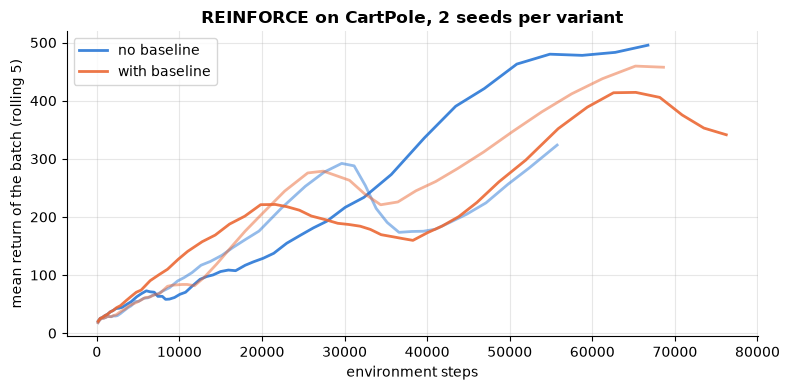

                    final return (last 5 updates)  env steps used
no baseline seed 0                          495.4         66734.0
no baseline seed 1                          323.6         55739.0
baseline seed 0                             341.4         76222.0
baseline seed 1                             457.6         68620.0


In [7]:
def collect_episodes(policy_net, n_episodes, env_seed, gamma=0.99):
    """Play n episodes in parallel (one env each). Returns per-episode lists of obs, actions, rewards-to-go, returns."""
    envs = [gym.make("CartPole-v1") for _ in range(n_episodes)]
    obs = [e.reset(seed=env_seed + i)[0] for i, e in enumerate(envs)]
    data = [{"obs": [], "act": [], "rew": []} for _ in envs]
    active = list(range(n_episodes))
    while active:
        with torch.no_grad():
            logits = policy_net(torch.as_tensor(np.array([obs[i] for i in active]), dtype=torch.float32))
            acts = torch.distributions.Categorical(logits=logits).sample().numpy()
        still = []
        for i, a in zip(active, acts):
            data[i]["obs"].append(obs[i]); data[i]["act"].append(int(a))
            obs[i], r, term, trunc, _ = envs[i].step(int(a)); data[i]["rew"].append(r)
            if not (term or trunc):
                still.append(i)
        active = still
    for d in data:                                         # rewards-to-go, computed backwards
        G, rtg = 0.0, []
        for r in reversed(d["rew"]):
            G = r + gamma * G; rtg.append(G)
        d["rtg"] = np.array(rtg[::-1], np.float32); d["return"] = sum(d["rew"])
    return data

def reinforce_loss(policy_net, value_net, batch, use_baseline):
    obs = torch.as_tensor(np.concatenate([d["obs"] for d in batch]), dtype=torch.float32)
    act = torch.as_tensor(np.concatenate([d["act"] for d in batch]))
    rtg = torch.as_tensor(np.concatenate([d["rtg"] for d in batch]))
    logp = torch.distributions.Categorical(logits=policy_net(obs)).log_prob(act)
    values = value_net(obs).squeeze(1)
    weight = rtg - values.detach() if use_baseline else rtg            # advantage estimate (or the raw return)
    policy_loss = -(logp * weight).sum() / len(batch)                  # average over episodes
    value_loss = F.mse_loss(values, rtg)
    return policy_loss, value_loss

def train_reinforce(n_updates=50, episodes_per_update=8, use_baseline=True, lr=5e-3, seed=0):
    torch.manual_seed(seed)
    policy_net, value_net = mlp(4, 2, 32), mlp(4, 1, 32)
    p_opt, v_opt = torch.optim.Adam(policy_net.parameters(), lr=lr), torch.optim.Adam(value_net.parameters(), lr=1e-2)
    curve, steps = [], 0
    for u in range(n_updates):
        batch = collect_episodes(policy_net, episodes_per_update, env_seed=seed * 100_000 + u * episodes_per_update)
        steps += sum(len(d["rew"]) for d in batch)
        pl, vl = reinforce_loss(policy_net, value_net, batch, use_baseline)
        p_opt.zero_grad(); pl.backward(); p_opt.step()
        v_opt.zero_grad(); vl.backward(); v_opt.step()                  # the value net is trained in both cases
        curve.append((steps, np.mean([d["return"] for d in batch])))
    return policy_net, value_net, np.array(curve)

t0 = time.time()
reinforce_runs = {(b, sd): train_reinforce(use_baseline=b, seed=sd) for b in [False, True] for sd in range(2)}
print(f"4 REINFORCE runs in {time.time() - t0:.0f} s")
plt.figure(figsize=(8, 4))
for (b, sd), (_, _, c) in reinforce_runs.items():
    plt.plot(c[:, 0], pd.Series(c[:, 1]).rolling(5, min_periods=1).mean(), color=PALETTE[int(b)], alpha=0.9 if sd == 0 else 0.5,
             label=("with baseline" if b else "no baseline") if sd == 0 else None)
plt.xlabel("environment steps"); plt.ylabel("mean return of the batch (rolling 5)")
plt.title("REINFORCE on CartPole, 2 seeds per variant"); plt.legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame({("baseline" if b else "no baseline") + f" seed {sd}": {"final return (last 5 updates)": c[-5:, 1].mean(),
                    "env steps used": c[-1, 0]} for (b, sd), (_, _, c) in reinforce_runs.items()}).T.round(1).to_string())

Learning curves mix many effects. Let's measure the **variance of the gradient estimate** directly: take one policy, collect 40 single-episode gradient estimates *from the same episodes* with and without the baseline, and compare their spread. Same episodes, same policy: the only difference is the baseline.

In [8]:
def flat_grad(policy_net, value_net, episode, use_baseline):
    policy_net.zero_grad()
    pl, _ = reinforce_loss(policy_net, value_net, [episode], use_baseline)
    pl.backward()
    return torch.cat([p.grad.flatten() for p in policy_net.parameters()]).clone()

pnet, vnet, _ = reinforce_runs[(True, 0)]                      # a partly trained policy and its value baseline
episodes = collect_episodes(pnet, 40, env_seed=777)
G_no = torch.stack([flat_grad(pnet, vnet, ep, False) for ep in episodes])
G_b = torch.stack([flat_grad(pnet, vnet, ep, True) for ep in episodes])
var_no = (G_no - G_no.mean(0)).pow(2).sum(1).mean().item()    # total variance = E||g - mean g||^2
var_b = (G_b - G_b.mean(0)).pow(2).sum(1).mean().item()
cos = F.cosine_similarity(G_no.mean(0), G_b.mean(0), dim=0).item()
print(f"Mean episode length in this sample: {np.mean([len(e['rew']) for e in episodes]):.0f} steps")
print(f"Total gradient variance  without baseline: {var_no:,.0f}   with baseline: {var_b:,.0f}   ratio: {var_no / var_b:.1f}x")
print(f"Cosine similarity of the two MEAN gradients: {cos:.2f}  (both estimate the same true gradient)")

Mean episode length in this sample: 389 steps
Total gradient variance  without baseline: 20,715,606   with baseline: 12,007,077   ratio: 1.7x
Cosine similarity of the two MEAN gradients: 0.94  (both estimate the same true gradient)


**What just happened?** With the same 40 episodes, the baseline cuts the variance of the gradient estimate by the ratio printed above. The two mean gradients point in a similar direction (the cosine similarity is positive), consistent with both being estimates of the same true gradient; with only 40 noisy samples they will not match exactly. Lower variance means each update is more reliable, so we can learn with fewer episodes or a larger step size. In the learning curves above, the baseline runs climb a little faster at first, but by the end the four runs overlap (one run without a baseline even finishes highest). With two seeds per variant, learning curves cannot settle the question, which is exactly why we measured the gradient variance directly.

> 🎓 **Exam / interview tip:** "Why doesn't a baseline bias the policy gradient?" Because $\mathbb E_{a\sim\pi}[\nabla_\theta\log\pi_\theta(a\mid s)\,b(s)] = b(s)\sum_a \nabla_\theta\pi_\theta(a\mid s) = b(s)\,\nabla_\theta 1 = 0$.

## 4. A2C: advantage actor-critic

> 💬 **In plain English:** a 'critic' network judges every move as it happens, so the 'actor' can improve without waiting for the game to end.

**Actor-critic** methods replace the full Monte Carlo return by a bootstrapped estimate from a learned **critic** $V_\phi$. **A2C** (the synchronous version of A3C, Mnih et al., 2016) collects $n$ steps from each of $N$ parallel environments and uses the **n-step advantage**

$$\hat A_t = R_{t+1} + \gamma R_{t+2} + \dots + \gamma^{n-1}R_{t+n} + \gamma^n V_\phi(S_{t+n}) - V_\phi(S_t).$$

The loss has three parts: policy loss $-\log\pi(A_t\mid S_t)\hat A_t$, value loss $c_v(\text{target} - V_\phi(S_t))^2$, and an **entropy bonus** $-c_e\,\mathcal H[\pi(\cdot\mid S_t)]$ that keeps the policy from becoming deterministic too early (an exploration aid). Unlike REINFORCE it updates every $n$ steps, not every episode.

We write one rollout function and one advantage function, and reuse both for PPO.

In [9]:
class ActorCritic(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=64):
        super().__init__()
        self.actor, self.critic = mlp(obs_dim, n_actions, hidden), mlp(obs_dim, 1, hidden)
    def dist(self, obs):
        return torch.distributions.Categorical(logits=self.actor(obs))
    def value(self, obs):
        return self.critic(obs).squeeze(-1)

def rollout(model, venv, n_steps, gamma, obs_transform=None):
    """Collect n_steps from every env. At time-limit truncations the reward gets + gamma * V(final obs) (bootstrap)."""
    tf = obs_transform or (lambda x, update=True: x)
    buf = {k: [] for k in ["obs", "act", "logp", "rew", "done", "val"]}
    obs = tf(venv.obs.copy())
    for _ in range(n_steps):
        o = torch.as_tensor(obs, dtype=torch.float32)
        with torch.no_grad():
            d = model.dist(o); a = d.sample(); v = model.value(o)
        next_obs, r, term, trunc, final_obs = venv.step(a.numpy())
        r = torch.as_tensor(r)
        if np.any(trunc & ~term):                                    # bootstrap through the time limit
            with torch.no_grad():
                v_final = model.value(torch.as_tensor(tf(final_obs, update=False), dtype=torch.float32))
            r = r + gamma * v_final * torch.as_tensor(trunc & ~term, dtype=torch.float32)
        for k, x in zip(buf, [o, a, d.log_prob(a), r, torch.as_tensor(term | trunc, dtype=torch.float32), v]):
            buf[k].append(x)
        obs = tf(next_obs)
    with torch.no_grad():
        last_v = model.value(torch.as_tensor(obs, dtype=torch.float32))
    return {k: torch.stack(v) for k, v in buf.items()}, last_v      # tensors of shape (n_steps, n_envs, ...)

def gae(rew, val, done, last_v, gamma, lam):
    """Generalised Advantage Estimation. lam = 1 gives n-step returns minus V (A2C); lam < 1 trades bias for variance."""
    T = len(rew); adv = torch.zeros_like(rew); running = torch.zeros_like(last_v)
    for t in reversed(range(T)):
        next_v = last_v if t == T - 1 else val[t + 1]
        delta = rew[t] + gamma * next_v * (1 - done[t]) - val[t]          # one-step TD error
        running = delta + gamma * lam * (1 - done[t]) * running          # discounted sum of TD errors
        adv[t] = running
    return adv, adv + val                                                # advantages and value targets

def train_a2c(total_steps=40_000, n_envs=8, n_steps=8, lr=1e-3, gamma=0.99, ent_coef=0.01, vf_coef=0.5, seed=0):
    torch.manual_seed(seed)
    venv, model = SimpleVecEnv(n_envs, seed=seed * 1000), ActorCritic()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    diag = []
    while venv.total_steps < total_steps:
        b, last_v = rollout(model, venv, n_steps, gamma)
        adv, ret = gae(b["rew"], b["val"], b["done"], last_v, gamma, lam=1.0)
        d = model.dist(b["obs"].flatten(0, 1))
        policy_loss = -(d.log_prob(b["act"].flatten()) * adv.flatten()).mean()
        value_loss = F.mse_loss(model.value(b["obs"].flatten(0, 1)), ret.flatten())
        entropy = d.entropy().mean()
        loss = policy_loss + vf_coef * value_loss - ent_coef * entropy
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 0.5); opt.step()
        diag.append((venv.total_steps, value_loss.item(), entropy.item()))
    return model, venv, np.array(diag)

t0 = time.time()
a2c_model, a2c_venv, a2c_diag = train_a2c()
with torch.no_grad():
    a2c_eval = evaluate(lambda o: int(a2c_model.dist(torch.as_tensor(o)).probs.argmax()))
print(f"A2C: {time.time() - t0:.0f} s, {a2c_venv.total_steps} env steps, greedy evaluation return {a2c_eval:.1f}")

A2C: 9 s, 40000 env steps, greedy evaluation return 167.9


**What just happened?** A2C updates after every 8 × 8 = 64 environment steps, using a critic to judge actions instead of waiting for whole episodes. We plot its curve together with PPO's in the next section. Its weakness is that each batch of experience is used for **one** gradient step and then thrown away. A large step can also wreck the policy, and the next batch is then collected with the wrecked policy. PPO addresses both.

## 5. PPO with GAE

> 💬 **In plain English:** PPO learns several times from the same experience but refuses to change its behaviour too much at once.

**Proximal Policy Optimization** (Schulman et al., 2017) reuses each batch for several epochs of mini-batch updates, but stops the new policy from moving too far from the policy that collected the data. With the probability ratio $r_t(\theta) = \pi_\theta(A_t\mid S_t)/\pi_{\theta_{\text{old}}}(A_t\mid S_t)$ it maximises the **clipped surrogate**

$$L^{\text{CLIP}}(\theta) = \mathbb E_t\Big[\min\big(r_t(\theta)\hat A_t,\ \operatorname{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon)\,\hat A_t\big)\Big].$$

For a good action ($\hat A > 0$) the objective stops rewarding increases of $r_t$ beyond $1 + \epsilon$; for a bad action it stops rewarding decreases below $1 - \epsilon$. So there is no incentive to change the policy more than about ε per update.

**GAE(λ)** (Schulman et al., 2016) computes advantages as an exponentially weighted sum of TD errors, $\hat A_t = \sum_k (\gamma\lambda)^k\delta_{t+k}$: λ = 0 is the one-step TD advantage (low variance, biased), λ = 1 is the Monte Carlo advantage. It is the TD(λ) idea from the tabular notebook, applied to advantages.

Diagnostics practitioners watch: **clip fraction** (the share of samples whose ratio was clipped; typically 0.05–0.3) and **approximate KL** between old and new policy (if it jumps far above ~0.02–0.05, the step is too large).

PPO: 14 s, 40448 env steps, greedy evaluation return 405.6


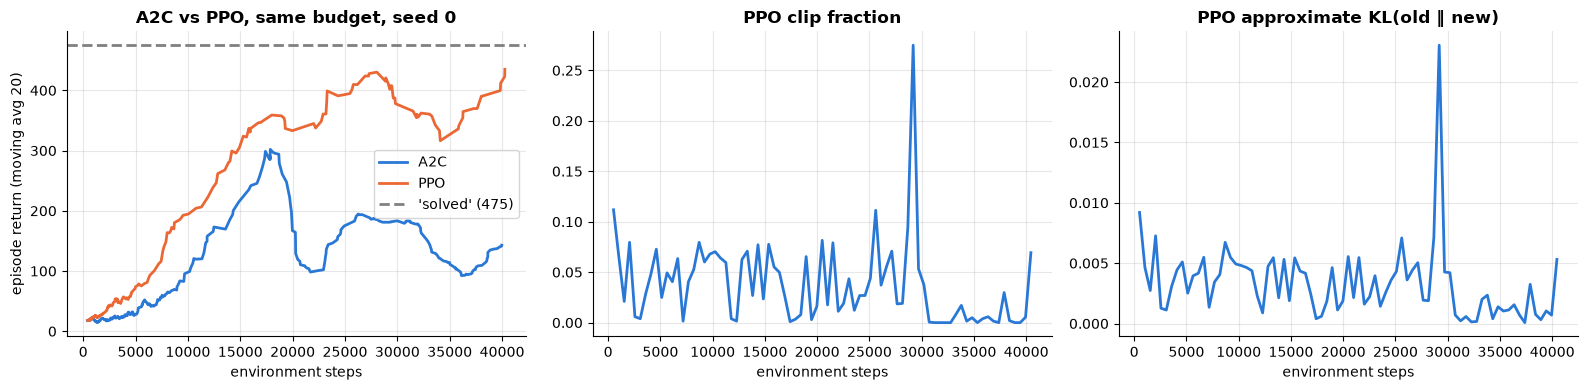

In [10]:
def train_ppo(total_steps=40_000, n_envs=8, n_steps=64, epochs=4, n_minibatches=4, lr=1e-3, gamma=0.99, lam=0.95,
              clip=0.2, ent_coef=0.0, vf_coef=0.5, seed=0, reward_scale=1.0, normalize_adv=True, obs_norm=None, wrapper=None):
    torch.manual_seed(seed)
    venv, model = SimpleVecEnv(n_envs, seed=seed * 1000, wrapper=wrapper), ActorCritic()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    diag = []
    while venv.total_steps < total_steps:
        b, last_v = rollout(model, venv, n_steps, gamma, obs_transform=obs_norm)
        b["rew"] = b["rew"] * reward_scale
        adv, ret = gae(b["rew"], b["val"], b["done"], last_v, gamma, lam)
        obs, act, old_logp = b["obs"].flatten(0, 1), b["act"].flatten(), b["logp"].flatten()
        adv, ret = adv.flatten(), ret.flatten()
        clipped, kls, vlosses = [], [], []
        for _ in range(epochs):                                           # reuse the same batch several times
            for idx in torch.randperm(len(obs)).chunk(n_minibatches):
                d = model.dist(obs[idx]); logp = d.log_prob(act[idx])
                ratio = (logp - old_logp[idx]).exp()
                a = adv[idx]
                if normalize_adv:
                    a = (a - a.mean()) / (a.std() + 1e-8)
                policy_loss = -torch.min(ratio * a, ratio.clamp(1 - clip, 1 + clip) * a).mean()
                value_loss = F.mse_loss(model.value(obs[idx]), ret[idx])
                loss = policy_loss + vf_coef * value_loss - ent_coef * d.entropy().mean()
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 0.5); opt.step()
                with torch.no_grad():
                    clipped.append(((ratio - 1).abs() > clip).float().mean().item())
                    kls.append(((ratio - 1) - (logp - old_logp[idx])).mean().item())   # low-variance KL estimator
                    vlosses.append(value_loss.item())
        diag.append((venv.total_steps, np.mean(clipped), np.mean(kls), np.mean(vlosses)))
    return model, venv, np.array(diag)

t0 = time.time()
ppo_model, ppo_venv, ppo_diag = train_ppo(seed=0)
with torch.no_grad():
    ppo_eval = evaluate(lambda o: int(ppo_model.dist(torch.as_tensor(o)).probs.argmax()))
print(f"PPO: {time.time() - t0:.0f} s, {ppo_venv.total_steps} env steps, greedy evaluation return {ppo_eval:.1f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(*learning_curve(a2c_venv), label="A2C"); axes[0].plot(*learning_curve(ppo_venv), label="PPO")
axes[0].axhline(475, color="grey", ls="--", label="'solved' (475)")
axes[0].set_xlabel("environment steps"); axes[0].set_ylabel("episode return (moving avg 20)"); axes[0].set_title("A2C vs PPO, same budget, seed 0"); axes[0].legend()
axes[1].plot(ppo_diag[:, 0], ppo_diag[:, 1]); axes[1].set_title("PPO clip fraction"); axes[1].set_xlabel("environment steps")
axes[2].plot(ppo_diag[:, 0], ppo_diag[:, 2]); axes[2].set_title("PPO approximate KL(old ‖ new)"); axes[2].set_xlabel("environment steps")
plt.tight_layout(); plt.show()

**What just happened?** With the same number of environment steps, PPO typically climbs much faster than A2C. It squeezes four epochs of updates out of every batch, and the clipping keeps those repeated updates safe. The diagnostics are in the healthy range: the clip fraction stays a modest fraction, and the approximate KL stays small. If you raise the learning rate a lot, you will see both jump and the learning curve become erratic. Try it.

> ⚠️ **Common mistake:** computing the ratio against the *current* policy's log-probabilities instead of the ones stored at collection time (`old_logp`). Then the ratio is always 1, clipping never happens, and PPO silently becomes a high-variance multi-epoch policy gradient.

> 🎓 **Exam / interview tip:** "Why is PPO the default for RLHF?" It is simple, works with large networks, reuses data for several epochs, and its trust-region-like clipping (plus a KL penalty to the reference model) keeps the language model from drifting into reward-hacking outputs.

## 6. Evaluating RL properly: seeds, IQM, confidence intervals

> 💬 **In plain English:** run the experiment several times and report the typical result with an honest error bar.

Deep RL results vary hugely between random seeds (Henderson et al., *Deep RL that Matters*, 2018). Reporting one run, or the best of five, is not evidence. Agarwal et al. (*Deep RL at the Edge of the Statistical Precipice*, NeurIPS 2021) recommend:
- run several seeds (≥ 5, more if you can) and report **aggregate** metrics with **confidence intervals**;
- prefer the **interquartile mean (IQM)**: the mean of the middle 50% of runs. It is more robust to outliers than the mean and more efficient than the median;
- use the **bootstrap** over runs for CIs, and show **learning curves with bands**, not single lines.

We train PPO with 5 seeds (seed 0 is the run above) and evaluate each final policy on 10 fixed evaluation episodes.

4 more PPO seeds trained in 55 s


final evaluation return per seed: {0: 405.6, 1: 500.0, 2: 500.0, 3: 407.1, 4: 153.5}
statistic  value 95% bootstrap CI
     mean  393.2   [273.2, 481.4]
   median  407.1   [153.5, 500.0]
      IQM  437.6   [237.5, 500.0]


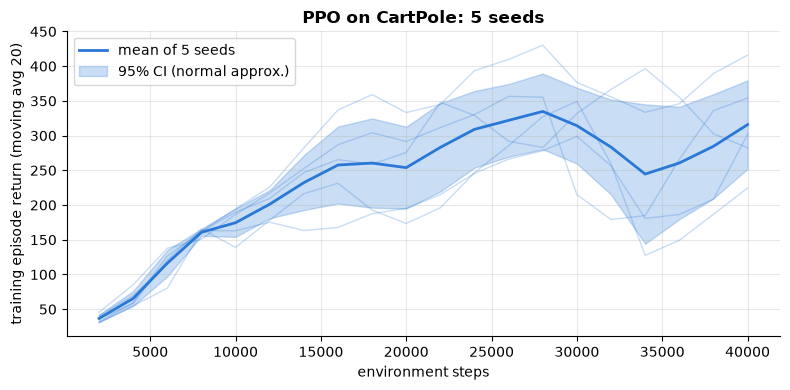

In [11]:
def iqm(x):
    x = np.sort(np.asarray(x)); n = len(x)
    lo, hi = int(np.floor(0.25 * n)), int(np.ceil(0.75 * n))
    return x[lo:hi].mean()

def bootstrap_ci(x, stat, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed); x = np.asarray(x)
    stats = [stat(rng.choice(x, len(x), replace=True)) for _ in range(n_boot)]
    return np.percentile(stats, [2.5, 97.5])

t0 = time.time()
ppo_seeds = {0: (ppo_model, ppo_venv)}
for sd in range(1, 5):
    m, v, _ = train_ppo(seed=sd)
    ppo_seeds[sd] = (m, v)
final_scores = {}
with torch.no_grad():
    for sd, (m, v) in ppo_seeds.items():
        final_scores[sd] = evaluate(lambda o: int(m.dist(torch.as_tensor(o)).probs.argmax()))
print(f"4 more PPO seeds trained in {time.time() - t0:.0f} s")
scores = np.array(list(final_scores.values()))
summary = pd.DataFrame({"statistic": ["mean", "median", "IQM"],
                        "value": [scores.mean(), np.median(scores), iqm(scores)],
                        "95% bootstrap CI": [bootstrap_ci(scores, np.mean).round(1), bootstrap_ci(scores, np.median).round(1), bootstrap_ci(scores, iqm).round(1)]})
print("final evaluation return per seed:", {k: round(v, 1) for k, v in final_scores.items()})
print(summary.round(1).to_string(index=False))

grid = np.arange(2_000, 40_001, 2_000)                                  # common x-axis for all seeds
curves = np.array([np.interp(grid, *learning_curve(v)) for _, v in ppo_seeds.values()])
mean, se = curves.mean(0), curves.std(0, ddof=1) / np.sqrt(len(curves))
plt.figure(figsize=(8, 4))
for c in curves:
    plt.plot(grid, c, color=PALETTE[0], alpha=0.25, lw=1)
plt.plot(grid, mean, color=PALETTE[0], label="mean of 5 seeds")
plt.fill_between(grid, mean - 1.96 * se, mean + 1.96 * se, alpha=0.25, color=PALETTE[0], label="95% CI (normal approx.)")
plt.xlabel("environment steps"); plt.ylabel("training episode return (moving avg 20)"); plt.title("PPO on CartPole: 5 seeds")
plt.legend(); plt.tight_layout(); plt.show()

**What just happened?** The thin lines are individual seeds: they rise at different speeds, and some plateau or dip for a while. The band is a 95% confidence interval for the mean curve. With 5 seeds the bootstrap CIs on the final score are wide; that is the honest statement of how much we know. IQM drops the best and worst runs before averaging, so one unlucky seed does not dominate the summary.

> 🎓 **Exam / interview tip:** when two algorithms' confidence intervals overlap heavily, you cannot claim one is better. Either run more seeds or report the comparison as inconclusive. See [`24_Research_Methods/03`](../24_Research_Methods/03_statistical_significance_and_reporting.ipynb) for paired tests and effect sizes.

## 7. Hyperparameter sensitivity

> 💬 **In plain English:** check how much the result depends on a few settings, so you know whether it is robust or lucky.

A method that only works with one magic learning rate is fragile. A small **sensitivity grid** tells you how fragile. We vary PPO's **learning rate** and **rollout length** `n_steps` (the batch per update is `n_envs × n_steps`), with a short budget of 15k steps and 2 seeds per cell, then sweep the discount **γ** separately.

Sensitivity runs: 82 s


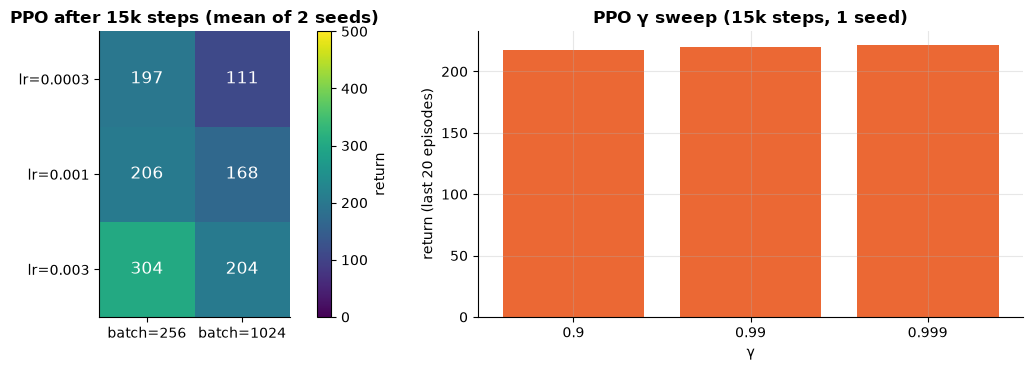

           batch=256  batch=1024
lr=0.0003      197.0       111.0
lr=0.001       206.0       168.0
lr=0.003       304.0       204.0
γ sweep: {0.9: np.float64(218.0), 0.99: np.float64(220.0), 0.999: np.float64(222.0)}


In [12]:
t0 = time.time()
lrs, rollouts = [3e-4, 1e-3, 3e-3], [32, 128]
grid_scores = pd.DataFrame(index=[f"lr={lr:g}" for lr in lrs], columns=[f"batch={8 * n}" for n in rollouts], dtype=float)
for lr in lrs:
    for n in rollouts:
        vals = []
        for sd in range(2):
            m, v, _ = train_ppo(total_steps=15_000, n_steps=n, lr=lr, seed=100 + sd)
            vals.append(np.mean(v.episode_returns[-20:]))              # average of the last 20 training episodes
        grid_scores.loc[f"lr={lr:g}", f"batch={8 * n}"] = np.mean(vals)
gamma_scores = {}
for g in [0.9, 0.99, 0.999]:
    m, v, _ = train_ppo(total_steps=15_000, gamma=g, seed=100)
    gamma_scores[g] = np.mean(v.episode_returns[-20:])
print(f"Sensitivity runs: {time.time() - t0:.0f} s")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
im = axes[0].imshow(grid_scores.values.astype(float), cmap="viridis", vmin=0, vmax=500)
for i in range(len(lrs)):
    for j in range(len(rollouts)):
        axes[0].text(j, i, f"{grid_scores.values[i, j]:.0f}", ha="center", va="center", color="white", fontsize=12)
axes[0].set_xticks(range(len(rollouts)), grid_scores.columns); axes[0].set_yticks(range(len(lrs)), grid_scores.index); axes[0].grid(False)
axes[0].set_title("PPO after 15k steps (mean of 2 seeds)"); plt.colorbar(im, ax=axes[0], label="return")
axes[1].bar([str(g) for g in gamma_scores], list(gamma_scores.values()), color=PALETTE[1])
axes[1].set_xlabel("γ"); axes[1].set_ylabel("return (last 20 episodes)"); axes[1].set_title("PPO γ sweep (15k steps, 1 seed)")
plt.tight_layout(); plt.show()
print(grid_scores.round(0).to_string()); print("γ sweep:", {g: round(s, 0) for g, s in gamma_scores.items()})

**What just happened?** The heatmap shows how much the outcome after a fixed budget depends on two "boring" settings. Within 15k steps, the larger learning rate and the smaller batch do best: larger batches give cleaner gradients but **fewer updates** for the same number of environment steps, and a small learning rate simply has not got far yet. The γ sweep shows almost no difference here: with γ = 0.9 the agent effectively looks only about $1/(1-\gamma) = 10$ steps ahead, and for balancing a pole that is already enough. On tasks with delayed rewards γ matters a lot. With only 1–2 seeds per cell, treat small differences as noise; the point is to spot **cliffs** (settings where training fails completely) and the direction of trends.

> ⚠️ **Common mistake:** tuning hyperparameters on the same seeds you report. Tune on one set of seeds (here 100, 101) and report on fresh ones (0–4 above).

## 8. Debugging RL

> 💬 **In plain English:** most RL failures come from numbers on the wrong scale; we break things on purpose and fix them.

When an RL agent does not learn, the bug is usually not in the "algorithm" but in the scale of numbers flowing through it. Here are two experiments and a checklist.

### 8.1 Reward scale and value-loss explosion
Suppose a reward is in cents instead of dollars (×100). The returns, and therefore the value targets, become 100× larger, so the squared value loss becomes about 10 000× larger. That loss dominates the shared gradient (and the gradient clipping), and the critic learns slowly.

Reward-scale runs: 17 s


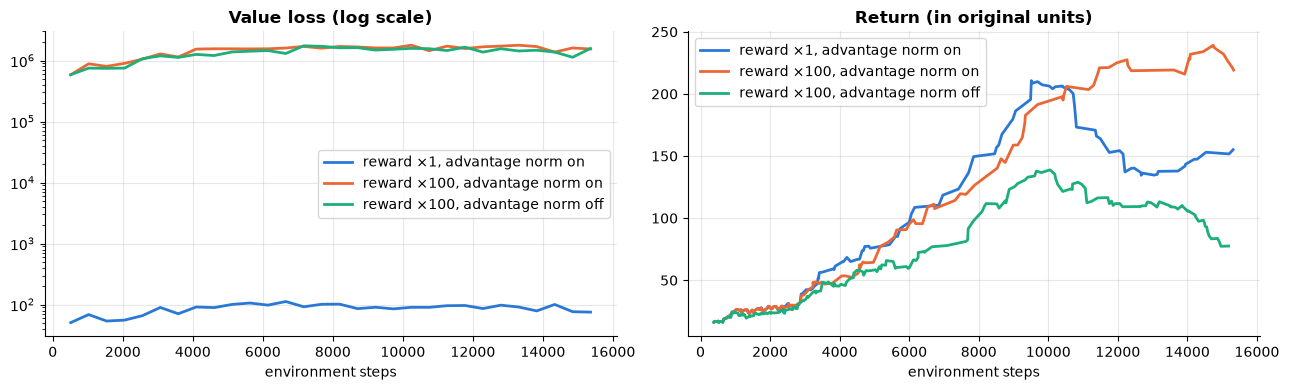

                    final value loss  last-20 return
×1, adv-norm on                 75.4           155.1
×100, adv-norm on          1545821.0           219.2
×100, adv-norm off         1578101.7            77.6


In [13]:
t0 = time.time()
scale_runs = {}
for scale, norm in [(1.0, True), (100.0, True), (100.0, False)]:
    m, v, diag = train_ppo(total_steps=15_000, reward_scale=scale, normalize_adv=norm, seed=7)
    scale_runs[(scale, norm)] = (v, diag)
print(f"Reward-scale runs: {time.time() - t0:.0f} s")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (scale, norm), (v, diag) in scale_runs.items():
    lab = f"reward ×{scale:g}, advantage norm {'on' if norm else 'off'}"
    axes[0].semilogy(diag[:, 0], diag[:, 3], label=lab); axes[1].plot(*learning_curve(v), label=lab)
axes[0].set_title("Value loss (log scale)"); axes[0].set_xlabel("environment steps"); axes[0].legend()
axes[1].set_title("Return (in original units)"); axes[1].set_xlabel("environment steps"); axes[1].legend()
plt.tight_layout(); plt.show()
print(pd.DataFrame({f"×{s:g}, adv-norm {'on' if n else 'off'}": {"final value loss": d[-1, 3], "last-20 return": np.mean(v.episode_returns[-20:])}
                    for (s, n), (v, d) in scale_runs.items()}).T.round(1).to_string())

**What just happened?** Multiplying the reward by 100 makes the value loss about 20,000 times larger (left plot, log scale). What happens to learning depends on the safeguards:
- **With advantage normalisation** the policy still learns (in this run even better than the ×1 run, which with one seed is within noise). Normalising advantages to mean 0 and standard deviation 1 in every mini-batch makes the *policy* update independent of the reward scale.
- **Without it**, the policy loss is 100× larger and the value loss about 10,000× larger. Both go into one total gradient that is clipped to norm 0.5, so the clipped direction is dominated by the critic's huge loss, and the policy barely improves.

Standard fixes: **scale or normalise rewards** (divide by a running standard deviation of returns), normalise advantages, clip or separately weight the value loss, and check the magnitude of every loss term in your logs.

### 8.2 Observation normalisation
Neural networks like inputs of order 1. CartPole's observations already are, so we simulate a badly scaled sensor: an `ObservationWrapper` that reports the cart position in **millimetres** and the pole angle in **millidegrees** (×1000 and ×57 296). A running mean/standard-deviation normaliser (Welford's algorithm, as in SB3's `VecNormalize`) fixes it.

Observation-normalisation runs: 12 s


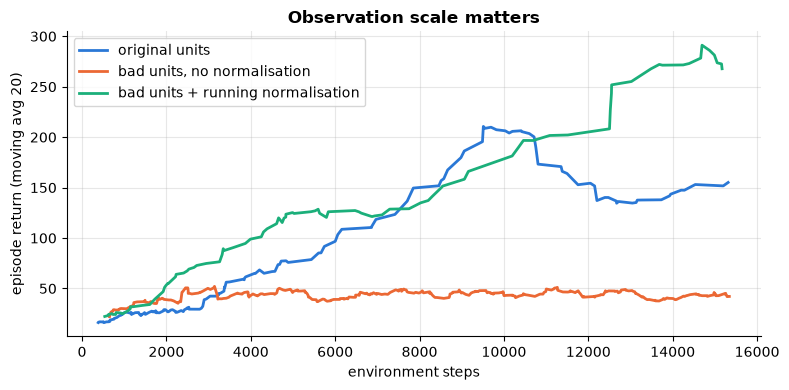

{'original units': 155.1, 'bad units, no normalisation': 42.1, 'bad units + running normalisation': 267.8}


In [14]:
class BadUnits(gym.ObservationWrapper):
    """Report x in millimetres and theta in millidegrees: the same information, terrible scale."""
    SCALE = np.array([1000.0, 1.0, 1000.0 * 180 / np.pi, 1.0], np.float32)
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(-np.inf, np.inf, (4,), np.float32)
    def observation(self, obs):
        return (obs * self.SCALE).astype(np.float32)

class RunningNorm:
    """Running mean and variance (parallel Welford update); normalise and clip to [-10, 10]."""
    def __init__(self, dim):
        self.mean, self.var, self.count = np.zeros(dim), np.ones(dim), 1e-4
    def __call__(self, x, update=True):
        if update:
            b_mean, b_var, b_n = x.mean(0), x.var(0), len(x)
            delta, tot = b_mean - self.mean, self.count + b_n
            self.mean = self.mean + delta * b_n / tot
            self.var = (self.var * self.count + b_var * b_n + delta ** 2 * self.count * b_n / tot) / tot
            self.count = tot
        return np.clip((x - self.mean) / np.sqrt(self.var + 1e-8), -10, 10).astype(np.float32)

t0 = time.time()
norm_runs = {"original units": train_ppo(total_steps=15_000, seed=7)[1],
             "bad units, no normalisation": train_ppo(total_steps=15_000, seed=7, wrapper=BadUnits)[1],
             "bad units + running normalisation": train_ppo(total_steps=15_000, seed=7, wrapper=BadUnits, obs_norm=RunningNorm(4))[1]}
print(f"Observation-normalisation runs: {time.time() - t0:.0f} s")
plt.figure(figsize=(8, 4))
for name, v in norm_runs.items():
    plt.plot(*learning_curve(v), label=name)
plt.xlabel("environment steps"); plt.ylabel("episode return (moving avg 20)"); plt.title("Observation scale matters"); plt.legend()
plt.tight_layout(); plt.show()
print({k: round(float(np.mean(v.episode_returns[-20:])), 1) for k, v in norm_runs.items()})

**What just happened?** The information is identical in all three runs, only the units differ. With inputs in the thousands, the first layer's tanh units saturate and gradients vanish, so learning stalls or becomes erratic. A running normaliser restores the performance (in this single-seed run it even beats the original units, which is within seed noise). Remember to **save the normaliser statistics with the model**: at deployment the policy must see inputs normalised exactly as during training.

### 8.3 RL debugging checklist

| Symptom | Likely cause | What to check / try |
|---|---|---|
| Return never beats random | bug in reward, done flags or action mapping | test the env with a scripted policy; print a few transitions |
| Value loss huge or growing | reward or return scale | normalise rewards or returns; clip value loss; lower the learning rate |
| Learns, then collapses | step too large; Q overestimation | lower the learning rate; PPO KL/clip-fraction; Double DQN; target-network period |
| Entropy drops to 0 fast | premature convergence | entropy bonus; check the advantage sign |
| Good in training, bad at evaluation | evaluating with exploration on/off differently; obs normaliser not saved | evaluate deterministically with frozen statistics |
| Agent "succeeds" in a weird way | reward hacking | watch rollouts; potential-based shaping (tabular notebook §8) |
| Results not reproducible | seeds, non-determinism | seed env, numpy, torch; report several seeds |

## 9. [optional] Stable-Baselines3: compare, save, load, roll out

> 💬 **In plain English:** the same job with a well-tested library, plus saving and loading the trained agent.

Libraries such as **Stable-Baselines3 (SB3)** contain tested implementations with all the details right (the "37 implementation details of PPO", Huang et al., 2022). In real projects you use a library, and your from-scratch knowledge lets you configure and debug it. This cell is skipped with a message if SB3 is not installed.

In [15]:
try:
    from stable_baselines3 import PPO as SB3_PPO
    from stable_baselines3.common.env_util import make_vec_env
    t0 = time.time()
    sb3_env = make_vec_env("CartPole-v1", n_envs=8, seed=0)
    sb3_model = SB3_PPO("MlpPolicy", sb3_env, n_steps=64, batch_size=128, n_epochs=4, learning_rate=1e-3,
                        gae_lambda=0.95, gamma=0.99, seed=0, device="cpu", verbose=0)
    sb3_model.learn(total_timesteps=40_000)
    sb3_score = evaluate(lambda o: int(sb3_model.predict(o, deterministic=True)[0]))
    tmp_dir = tempfile.mkdtemp()
    try:
        path = os.path.join(tmp_dir, "ppo_cartpole")
        sb3_model.save(path)                                            # writes ppo_cartpole.zip
        loaded = SB3_PPO.load(path, device="cpu")
        reloaded_score = evaluate(lambda o: int(loaded.predict(o, deterministic=True)[0]))
        size_kb = os.path.getsize(path + ".zip") / 1024
    finally:
        shutil.rmtree(tmp_dir)                                          # clean up the temporary folder
    print(f"SB3 PPO: {time.time() - t0:.0f} s, evaluation return {sb3_score:.1f}; after save+load: {reloaded_score:.1f} (file {size_kb:.0f} KB)")
    print(f"Our from-scratch PPO (seed 0, same budget): {ppo_eval:.1f}")
except ImportError:
    print("stable-baselines3 is not installed: skipping this optional comparison (pip install stable-baselines3).")

SB3 PPO: 14 s, evaluation return 500.0; after save+load: 500.0 (file 138 KB)
Our from-scratch PPO (seed 0, same budget): 405.6


**What just happened?** With the same budget and similar hyperparameters, SB3's PPO reached the maximum score and ours (seed 0) about 400: the same range, given that our five seeds in section 6 ranged from about 150 to 500. SB3 also includes small refinements (for example orthogonal weight initialisation) that make it more reliable across seeds, which is one reason libraries are the default in practice. The saved `.zip` holds the network weights and the hyperparameters, and the reloaded policy behaves identically (same evaluation seeds, deterministic actions). For a production-style workflow with SB3 (custom Gymnasium environment, baselines, guardrails, tests), see [`08_industry_inventory_control_with_rl`](08_industry_inventory_control_with_rl.ipynb).

## 10. Summary table

> 💬 **In plain English:** one table comparing the algorithms.

| Algorithm | Type | On/off-policy | Data reuse | Key stabiliser | Strength | Weakness |
|---|---|---|---|---|---|---|
| DQN | value-based | off | replay buffer (high) | target network, Huber loss | sample-efficient, discrete actions | overestimation, instability, discrete actions only |
| Double DQN | value-based | off | high | decoupled argmax/evaluation | less overestimation | same family limits |
| REINFORCE | policy gradient (MC) | on | none (one update per batch of episodes) | baseline | simple, unbiased | high variance, slow |
| A2C | actor-critic | on | none | critic, entropy bonus | low variance, online | one gradient step per batch |
| PPO | actor-critic | on | a few epochs per batch | clipped ratio, GAE | robust default, scales to LLMs | many implementation details, still on-policy |

Rough complexity per update: DQN $O(B\,|\theta|)$ per gradient step; policy-gradient methods $O(N\,T\,|\theta|)$ per batch of $N$ environments × $T$ steps (times the number of epochs for PPO).

## 11. 🔗 How this connects to modern AI

> 💬 **In plain English:** these same algorithms train chatbots (RLHF), reasoning models, robots and business systems.

- **RLHF** for chat models (InstructGPT, 2022) is PPO with the language model as the policy, a learned reward model as the reward, and a KL penalty to the supervised model as the "stay close" stabiliser. Read [`08_LLM/12_alignment_techniques`](../08_LLM/12_alignment_techniques.ipynb), then do DPO by hand in [`08_LLM/21_fine_tuning_hands_on_cpu`](../08_LLM/21_fine_tuning_hands_on_cpu.ipynb).
- **Reasoning models** trained with RL on verifiable rewards (e.g. DeepSeek-R1, 2025) use **GRPO**, a PPO variant that drops the critic and uses the group-relative return of several sampled answers as the baseline. It is the baseline trick of section 3 at LLM scale ([`08_LLM/18_reasoning_models`](../08_LLM/18_reasoning_models.ipynb)).
- **Robotics and control:** PPO and SAC trained in fast simulators, then transferred to real robots (sim-to-real), rely on the observation-normalisation and reward-scaling tricks of section 8.
- **Games:** DQN learned Atari from pixels (2015); AlphaStar and OpenAI Five used large-scale actor-critic methods.
- **Operations:** inventory, pricing and bidding policies ([`08_industry_inventory_control_with_rl`](08_industry_inventory_control_with_rl.ipynb)) are trained with these algorithms and must be evaluated with the seed-aware statistics of section 6.

## 12. Recap

> 💬 **In plain English:** key points, practice and further reading.

- Always start with **baselines** (random, heuristic) and a correct **environment interface**: `terminated` (failure, no bootstrap) is not `truncated` (time limit, bootstrap).
- **DQN** = Q-learning + replay buffer + target network + Huber loss; **Double DQN** reduces the upward bias of $\max$.
- **REINFORCE** is unbiased but noisy; a learned **baseline** keeps it unbiased and reduces the gradient variance (we measured the ratio).
- **A2C** uses a critic and n-step advantages; **PPO** adds safe multi-epoch reuse via the **clipped ratio** and **GAE(λ)** advantages.
- Evaluate with **several seeds**, **IQM** and **bootstrap CIs**; plot learning curves with bands.
- Sensitivity grids reveal fragile hyperparameters; **reward scale** and **observation scale** are the most common silent bugs.

## Practice problems

**1. (Conceptual, easy)** Why must a DQN replay buffer store `terminated` rather than `terminated or truncated` as its done flag? What goes wrong otherwise?

<details><summary>Show solution</summary>

A time-limit truncation at step 500 does not mean the pole fell. The true value of that state is about $1/(1-\gamma) = 100$ for a good policy. If we store `done = True`, the target becomes just $r = 1$, so the network learns that states near step 500 are worth almost nothing. Since the observation does not include the time, those identical-looking states get contradictory targets, which slows or destabilises learning. Correct: store `done = terminated` and the true final observation, so that $y = r + \gamma \max_a Q(s_{\text{final}}, a)$.

</details>

**2. (Calculation, easy)** In PPO with ε = 0.2, compute the clipped objective term for (a) $\hat A = 0.5$, ratio $r = 1.5$; (b) $\hat A = -0.5$, $r = 0.5$. In each case, does the gradient push the ratio further?

<details><summary>Show solution</summary>

$\hat A = 0.5$, $\epsilon = 0.2$.
- If $r = 1.5$: unclipped term $1.5 \times 0.5 = 0.75$; clipped $\operatorname{clip}(1.5, 0.8, 1.2) \times 0.5 = 0.6$; min = **0.6**. The gradient with respect to θ is zero (the clipped branch is constant), so there is no push to increase the ratio further.
- If $\hat A = -0.5$ and $r = 0.5$: unclipped $-0.25$, clipped $0.8 \times -0.5 = -0.4$; min = **−0.4**, again the clipped constant, so no push to decrease the probability further.

</details>

**3. (Proof, medium)** Prove that subtracting an action-independent baseline $b(s)$ leaves the policy gradient unbiased.

<details><summary>Show solution</summary>

$$\mathbb E_{a\sim\pi_\theta}\big[\nabla_\theta \log\pi_\theta(a\mid s)\, b(s)\big] = b(s)\sum_a \pi_\theta(a\mid s)\frac{\nabla_\theta\pi_\theta(a\mid s)}{\pi_\theta(a\mid s)} = b(s)\,\nabla_\theta\sum_a\pi_\theta(a\mid s) = b(s)\,\nabla_\theta 1 = 0.$$
The baseline cannot depend on the action $a$; otherwise it cannot be pulled out of the sum and the argument fails.

</details>

**4. (Coding, easy)** Write `iqm` and compute it for final scores `[10, 200, 210, 220, 500]`. Compare with the mean.

<details><summary>Show solution</summary>

```python
def iqm(x):
    x = np.sort(np.asarray(x)); n = len(x)
    lo, hi = int(np.floor(0.25 * n)), int(np.ceil(0.75 * n))
    return x[lo:hi].mean()

print(iqm([10, 200, 210, 220, 500]))    # middle 50% of 5 runs = indices 1..3 -> (200+210+220)/3 = 210.0
print(np.mean([10, 200, 210, 220, 500]))  # 228.0, pulled by the extremes
```
For $n = 5$, $\lfloor 1.25\rfloor = 1$ and $\lceil 3.75\rceil = 4$, so the middle three runs are averaged. (The `rliable` library uses a slightly different interpolation for non-multiples of 4; the idea is the same.)

</details>

**5. (Coding, medium)** Replace DQN's hard target update with a **soft (Polyak) update** $\bar\theta \leftarrow (1-\tau)\bar\theta + \tau\theta$ after every gradient step.

<details><summary>Show solution</summary>

```python
@torch.no_grad()
def soft_update(target, online, tau=0.005):
    """Polyak averaging: target <- (1 - tau) * target + tau * online, parameter by parameter."""
    for p_t, p in zip(target.parameters(), online.parameters()):
        p_t.mul_(1 - tau).add_(tau * p)

# Check on two tiny networks
online, target = nn.Linear(2, 1), nn.Linear(2, 1)
expected = 0.995 * target.weight.detach().clone() + 0.005 * online.weight.detach()
soft_update(target, online)
print(torch.allclose(target.weight, expected))     # True
```
In `train_dqn`, delete the `if step % target_every < n_envs:` block and call `soft_update(q_target, q)` right after `opt.step()`. With τ = 0.005 the target network lags the online one by roughly $1/\tau = 200$ gradient steps: a smooth version of the hard copy every C steps. SAC, TD3 and DDPG use this soft update.

</details>

**6. (Coding, medium)** Check the `gae` function by hand on a 3-step rollout with rewards 1, 1, 1, values 0.5, 0.4, 0.3, bootstrap value 0.2, γ = 0.9, for λ = 0 and λ = 1.

<details><summary>Show solution</summary>

```python
# uses gae() from section 4
rew = torch.tensor([[1.], [1.], [1.]]); val = torch.tensor([[0.5], [0.4], [0.3]])
done = torch.zeros(3, 1); last_v = torch.tensor([0.2])
adv0, _ = gae(rew, val, done, last_v, 0.9, 0.0)    # lambda = 0: one-step TD errors
adv1, _ = gae(rew, val, done, last_v, 0.9, 1.0)    # lambda = 1: n-step return minus V
print(adv0.squeeze().tolist())   # [1 + 0.9*0.4 - 0.5, 1 + 0.9*0.3 - 0.4, 1 + 0.9*0.2 - 0.3] = [0.86, 0.87, 0.88]
print(adv1.squeeze().tolist())   # G_0 = 1 + 0.9 + 0.81 + 0.729*0.2 = 2.8558 -> 2.3558, then 1.662, 0.88
```

</details>

**7. (Research design, hard)** A colleague shows a plot of 2 seeds each and claims "our PPO variant beats A2C". Design a protocol that would make the claim credible.

<details><summary>Show solution</summary>

Two seeds per variant is far too few: seed-to-seed variation in RL is of the same order as the effect. A credible protocol: (1) fix the budget and the evaluation protocol (e.g. 10 fixed evaluation episodes, deterministic actions); (2) run ≥ 10 seeds per variant with *different* seeds from those used for tuning; (3) report IQM with stratified-bootstrap 95% CIs, plus learning curves with bands; (4) if comparing two methods on the same seeds, use a paired test (e.g. a permutation test on per-seed differences) and report the effect size; (5) state the compute used. An alternative to more seeds is the "performance profile" (fraction of runs above each score threshold) from Agarwal et al. (2021).

</details>

## Further reading
- Sutton & Barto, *Reinforcement Learning: An Introduction*, 2nd ed. (2018), ch. 9–13 (function approximation, policy gradients), free at [incompleteideas.net/book](http://incompleteideas.net/book/the-book-2nd.html).
- Mnih et al. (2015), "Human-level control through deep reinforcement learning", *Nature* (DQN); van Hasselt, Guez & Silver (2016), "Deep RL with Double Q-learning", AAAI.
- Schulman et al. (2016), "High-dimensional continuous control using GAE", ICLR; Schulman et al. (2017), "Proximal Policy Optimization Algorithms", arXiv:1707.06347.
- Henderson et al. (2018), "Deep Reinforcement Learning that Matters", AAAI; Agarwal et al. (2021), "Deep RL at the Edge of the Statistical Precipice", NeurIPS.
- Huang et al. (2022), "The 37 Implementation Details of Proximal Policy Optimization", ICLR blog track.
- OpenAI [Spinning Up in Deep RL](https://spinningup.openai.com/) (free, clear derivations and code).

## Next notebook
➡️ [`08_LLM/21_fine_tuning_hands_on_cpu.ipynb`](../08_LLM/21_fine_tuning_hands_on_cpu.ipynb): supervised fine-tuning, LoRA and DPO on a tiny language model, the LLM side of "reinforcement learning from feedback".

In [16]:
print(f"Notebook finished in {time.time() - NOTEBOOK_START:.0f} s")

Notebook finished in 309 s
